In [1]:
import numpy as np
import pandas as pd
from tensorflow.keras.utils import to_categorical 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Dropout,Activation,Flatten


In [2]:
data = pd.read_csv("/kaggle/input/datasets/ossamasamir/onecircle/one_circle.csv")

In [3]:
data = data.drop(columns=['Unnamed: 0'])

In [4]:
data.head()

,x_1,x_2,y
0,-0.759416,2.753240,0
1,-1.885278,1.629527,0
2,2.463302,-1.023869,0
3,-1.986004,-0.898810,0
4,2.010834,-2.580117,0


In [5]:
X = data.drop('y', axis=1)
y = data['y']

In [6]:
X.head()

,x_1,x_2
0,-0.759416,2.753240
1,-1.885278,1.629527
2,2.463302,-1.023869
3,-1.986004,-0.898810
4,2.010834,-2.580117


In [7]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: y, dtype: int64

In [8]:
categorized_y = np.array(to_categorical(y,2))

In [9]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: y, dtype: int64

In [10]:
model = Sequential()

In [11]:
model.add(Dense(128,activation='relu',input_shape=(2,)))
model.add(Dropout(0.2))
model.add(Dense(64,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(2,activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-10-07 16:11:35.180867: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [12]:
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [13]:
model.fit(X,categorized_y,epochs=100,batch_size=10)

Epoch 1/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7364 - loss: 0.5427
Epoch 2/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4639 
Epoch 3/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4590 
Epoch 4/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4618 
Epoch 5/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4538 
Epoch 6/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4319 
Epoch 7/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4405 
Epoch 8/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4434 
Epoch 9/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4080 
Epoch 10/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4339 
Epoch 11/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7636 - loss: 0.4125 
Epoch 12/100
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step -

## Training a neural network for image recognition

In [14]:
from tensorflow import keras
import matplotlib.pyplot as plt

In [15]:
(X_train,y_train),(X_test,y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


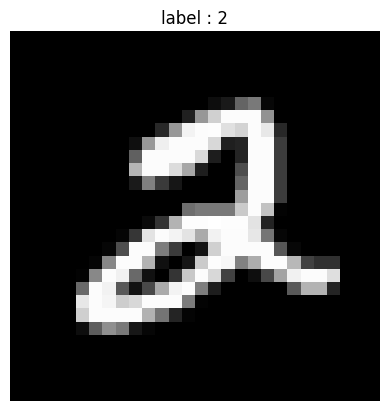

In [16]:
plt.imshow(X_train[5], cmap='gray')
plt.title(f"label : {y_train[5]}")
plt.axis('off')
plt.show()


### By Loop 

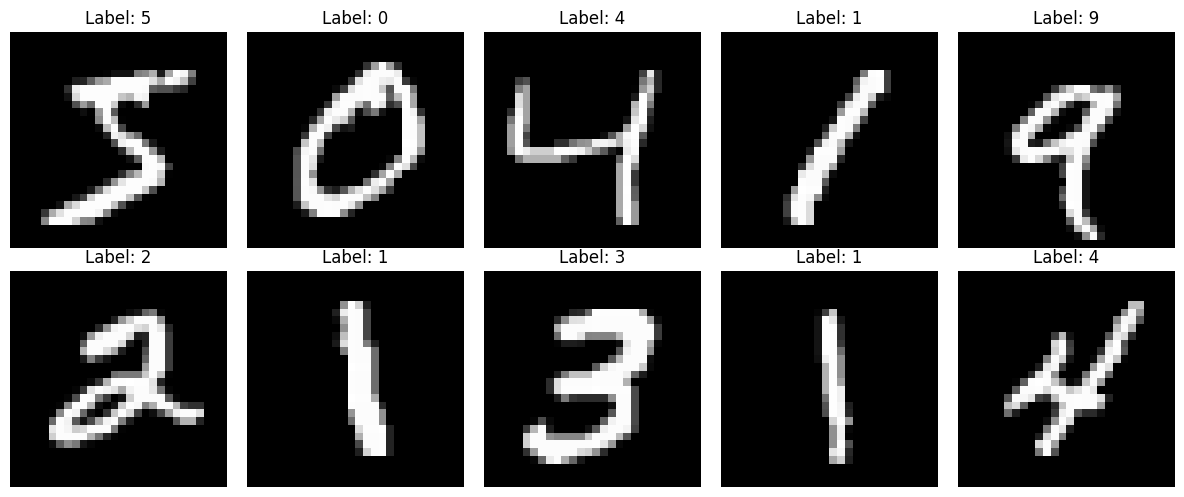

In [17]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

In [18]:
X_train_reshaped = X_train.reshape(-1,28*28)
X_test_reshaped = X_test.reshape(-1,28*28)

In [19]:
y_train_cate = to_categorical(y_train,10)
y_test_cate = to_categorical(y_test,10)

In [20]:
y_train_cate[5]

array([0., 0., 1., 0., 0., 0., 0., 0., 0., 0.])

In [21]:
model = Sequential()

In [22]:
model.add(Dense(128,activation='relu',input_shape=(28*28,)))
model.add(Dropout(0.2))
model.add(Dense(24,activation='relu'))
model.add(Dropout(0.2))
model.add(Dense(10,activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [23]:
model.compile(loss='categorical_crossentropy',optimizer='adam',metrics=['accuracy'])

In [24]:
model.fit(X_train_reshaped,y_train_cate,epochs=10,batch_size=10)

Epoch 1/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 20s 3ms/step - accuracy: 0.1339 - loss: 2.5288
Epoch 2/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.1292 - loss: 2.2979
Epoch 3/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.1612 - loss: 2.2109
Epoch 4/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.1796 - loss: 2.1428
Epoch 5/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 21s 3ms/step - accuracy: 0.1933 - loss: 2.0729
Epoch 6/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.1969 - loss: 2.0755
Epoch 7/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.2008 - loss: 2.0545
Epoch 8/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 19s 3ms/step - accuracy: 0.2014 - loss: 2.0431
Epoch 9/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.2031 - loss: 2.0401
Epoch 10/10
6000/6000 ━━━━━━━━━━━━━━━━━━━━ 18s 3ms/step - accuracy: 0.2044 - loss: 2.0216


In [25]:
prediction_vector = model.predict(X_train_reshaped)

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


In [26]:
prediction = [np.argmax(pred) for pred in prediction_vector]

In [27]:
loss , accuracy = model.evaluate(X_test_reshaped,y_test_cate)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.2064 - loss: 2.0168


In [28]:
print(accuracy)

0.20640000700950623


# Improved

In [29]:
# Load data
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

In [30]:
# Normalize pixels
X_train = X_train / 255.0
X_test = X_test / 255.0

In [31]:
# Model
model = Sequential()

model.add(Flatten(input_shape=(28, 28)))

model.add(Dense(128, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(64, activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(10, activation='softmax'))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [32]:
# Compile
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [33]:
# Train
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - accuracy: 0.8917 - loss: 0.3618 - val_accuracy: 0.9564 - val_loss: 0.1490
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9478 - loss: 0.1717 - val_accuracy: 0.9658 - val_loss: 0.1143
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9586 - loss: 0.1359 - val_accuracy: 0.9694 - val_loss: 0.1035
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9664 - loss: 0.1114 - val_accuracy: 0.9715 - val_loss: 0.0957
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9693 - loss: 0.1008 - val_accuracy: 0.9771 - val_loss: 0.0803
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9727 - loss: 0.0851 - val_accuracy: 0.9726 - val_loss: 0.0923
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9739 - loss: 0.0805 - val_accuracy: 0.9759 - val_loss: 0.0820
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9766 - loss: 0.0738 - 

In [34]:
# Test
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9775 - loss: 0.0779
Test Accuracy: 0.9775000214576721


# Neural networks for regression

In [35]:
housing = pd.read_csv('/kaggle/input/datasets/ossamasamir/hyderabad/Hyderabad.csv')

In [36]:
housing.head()

,Price,Area,Location,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
0,6968000,1340,Nizampet,2,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
1,29000000,3498,Hitech City,4,0,0,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
2,6590000,1318,Manikonda,2,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,5739000,1295,Alwal,3,1,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,5679000,1145,Kukatpally,2,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,0,0


In [37]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2518 entries, 0 to 2517
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Price                2518 non-null   int64 
 1   Area                 2518 non-null   int64 
 2   Location             2518 non-null   object
 3   No. of Bedrooms      2518 non-null   int64 
 4   Resale               2518 non-null   int64 
 5   MaintenanceStaff     2518 non-null   int64 
 6   Gymnasium            2518 non-null   int64 
 7   SwimmingPool         2518 non-null   int64 
 8   LandscapedGardens    2518 non-null   int64 
 9   JoggingTrack         2518 non-null   int64 
 10  RainWaterHarvesting  2518 non-null   int64 
 11  IndoorGames          2518 non-null   int64 
 12  ShoppingMall         2518 non-null   int64 
 13  Intercom             2518 non-null   int64 
 14  SportsFacility       2518 non-null   int64 
 15  ATM                  2518 non-null   int64 
 16  ClubHo

In [38]:
housing['Location'].nunique()

243

In [39]:
housing.shape

(2518, 40)

In [40]:
feature = housing.drop(['Location', 'Price'], axis=1)

In [41]:
feature

,Area,No. of Bedrooms,Resale,MaintenanceStaff,Gymnasium,SwimmingPool,LandscapedGardens,JoggingTrack,RainWaterHarvesting,IndoorGames,...,LiftAvailable,BED,VaastuCompliant,Microwave,GolfCourse,TV,DiningTable,Sofa,Wardrobe,Refrigerator
0,1340,2,0,0,1,1,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
1,3498,4,0,0,1,1,1,1,1,1,...,1,0,1,0,0,0,0,0,0,0
2,1318,2,0,0,1,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
3,1295,3,1,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,1145,2,0,0,0,0,1,0,0,0,...,1,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2513,1460,2,1,9,9,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
2514,1314,2,1,9,9,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
2515,2625,3,1,9,9,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9
2516,2050,3,0,9,9,9,9,9,9,9,...,9,9,9,9,9,9,9,9,9,9


In [42]:
labels = housing['Price']
labels

0        6968000
1       29000000
2        6590000
3        5739000
4        5679000
          ...   
2513    11000000
2514    26000000
2515    13300000
2516    10800000
2517    10400000
Name: Price, Length: 2518, dtype: int64

**Building and training the neural network**

In [43]:
model = Sequential()

In [44]:
model.add(Dense(38, activation='relu', input_shape=(38,)))
model.add(Dropout(0.2))

model.add(Dense(128,activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(64,activation='relu'))
model.add(Dropout(0.2))

model.add(Dense(1))


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [45]:
# Compiling the model. The metrics flag is added for the model to report the root mean squared error at each epoch.
model.compile(loss = 'mean_squared_error', optimizer='adam', metrics=[keras.metrics.RootMeanSquaredError()])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_9 (Dense)                 │ (None, 38)             │         1,482 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 38)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 128)            │         4,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,795 (57.79 KB)

 Trainable params: 14,795 (57.79 KB)

 Non-trainable params: 0 (0.00 B)

In [46]:
model.fit(feature,labels,epochs=10,batch_size=10)

Epoch 1/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 153280453804032.0000 - root_mean_squared_error: 12380648.0000
Epoch 2/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 38674691522560.0000 - root_mean_squared_error: 6218898.0000
Epoch 3/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 33825927200768.0000 - root_mean_squared_error: 5816006.0000
Epoch 4/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 33486603812864.0000 - root_mean_squared_error: 5786761.0000
Epoch 5/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 32688652156928.0000 - root_mean_squared_error: 5717399.0000
Epoch 6/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 35580880617472.0000 - root_mean_squared_error: 5964971.0000
Epoch 7/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 33978341916672.0000 - root_mean_squared_error: 5829094.5000
Epoch 8/10
252/252 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 33772351258624.0000 - root_mean_squared_error: 5811398.5000
Epoch 9/10
252/252 ━━━━━━━━━━━━━━━━━━━

In [47]:
model.evaluate(feature, labels)

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 30665340878848.0000 - root_mean_squared_error: 5537629.5000


[30665340878848.0, 5537629.5]